<a href="https://www.kaggle.com/code/lalit7881/layoffs-eda-69-34?scriptVersionId=370659692" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns 
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/swaptr/layoffs-2022/layoffs.csv


In [2]:
df = pd.read_csv("/kaggle/input/datasets/swaptr/layoffs-2022/layoffs.csv")

In [3]:
df.head()

,company,location,total_laid_off,date,percentage_laid_off,industry,source,stage,funds_raised,country,date_added
0,Qualcomm,"Bengaluru, Non-U.S.",1500.0,11/11/2026,NaN,Hardware,https://timesofindia.indiatimes.com/business/i...,Post-IPO,NaN,India,11/14/2026
1,Innoviz,"Tel Aviv, Non-U.S.",80.0,11/11/2026,0.2,Transportation,https://www.calcalistech.com/ctechnews/article...,Post-IPO,547.0,Israel,11/14/2026
2,Polymarket,New York City,NaN,11/11/2026,NaN,Finance,https://www.reuters.com/business/polymarket-cu...,Series E,2300.0,United States,11/14/2026
3,Val Town,New York City,NaN,11/10/2026,1.0,Product,https://blog.val.town/winding-down,Seed,7.0,United States,11/14/2026
4,Coursera,SF Bay Area,NaN,11/9/2026,0.1,Education,https://ca.investing.com/news/stock-market-new...,Acquired,458.0,United States,11/14/2026


In [4]:
df.tail()

,company,location,total_laid_off,date,percentage_laid_off,industry,source,stage,funds_raised,country,date_added
4670,Service,Los Angeles,NaN,3/16/2020,1.00,Travel,https://techcrunch.com/2020/03/16/travel-savin...,Seed,5.1,United States,8/31/2020
4671,HopSkipDrive,Los Angeles,8.0,3/13/2020,0.10,Transportation,https://layoffs.fyi/2020/04/02/hopskipdrive-la...,Unknown,45.0,United States,4/3/2020
4672,Panda Squad,SF Bay Area,6.0,3/13/2020,0.75,Consumer,https://twitter.com/danielsinger/status/123854...,Seed,1.0,United States,4/17/2020
4673,Tamara Mellon,Los Angeles,20.0,3/12/2020,0.40,Retail,https://layoffs.fyi/list/tamara-mellon/,Series C,90.0,United States,3/31/2020
4674,EasyPost,Salt Lake City,75.0,3/11/2020,NaN,Logistics,https://www.bizjournals.com/louisville/news/20...,Series A,12.0,United States,3/31/2020


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4675 entries, 0 to 4674
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   company              4675 non-null   object 
 1   location             4674 non-null   object 
 2   total_laid_off       3048 non-null   float64
 3   date                 4675 non-null   object 
 4   percentage_laid_off  2917 non-null   float64
 5   industry             4673 non-null   object 
 6   source               4672 non-null   object 
 7   stage                4667 non-null   object 
 8   funds_raised         4119 non-null   float64
 9   country              4673 non-null   object 
 10  date_added           4675 non-null   object 
dtypes: float64(3), object(8)
memory usage: 401.9+ KB


In [6]:
df.describe()

,total_laid_off,percentage_laid_off,funds_raised
count,3048.000000,2917.000000,4119.000000
mean,310.842848,0.296645,968.047850
std,1107.054528,0.307720,5574.124313
min,3.000000,0.000000,0.700000
25%,40.000000,0.100000,56.000000
50%,90.000000,0.170000,177.000000
75%,200.000000,0.330000,489.000000
max,22000.000000,1.000000,121900.000000


In [7]:
df.isnull().sum()

company                   0
location                  1
total_laid_off         1627
date                      0
percentage_laid_off    1758
industry                  2
source                    3
stage                     8
funds_raised            556
country                   2
date_added                0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.dtypes

company                 object
location                object
total_laid_off         float64
date                    object
percentage_laid_off    float64
industry                object
source                  object
stage                   object
funds_raised           float64
country                 object
date_added              object
dtype: object

In [10]:
df.shape

(4675, 11)

In [11]:
df.columns

Index(['company', 'location', 'total_laid_off', 'date', 'percentage_laid_off',
       'industry', 'source', 'stage', 'funds_raised', 'country', 'date_added'],
      dtype='object')

In [12]:
df.nunique()

company                3017
location                274
total_laid_off          388
date                   1348
percentage_laid_off      82
industry                 30
source                 4411
stage                    16
funds_raised            773
country                  67
date_added             1125
dtype: int64

## EDA

In [13]:

# ============================================
# 1. IMPORT LIBRARIES
# ============================================

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    HistGradientBoostingClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

sns.set_theme(style="whitegrid", palette="husl")


print("Dataset Shape:", df.shape)

display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include='all').T)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())


Dataset Shape: (4675, 11)


,company,location,total_laid_off,date,percentage_laid_off,industry,source,stage,funds_raised,country,date_added
0,Qualcomm,"Bengaluru, Non-U.S.",1500.0,11/11/2026,NaN,Hardware,https://timesofindia.indiatimes.com/business/i...,Post-IPO,NaN,India,11/14/2026
1,Innoviz,"Tel Aviv, Non-U.S.",80.0,11/11/2026,0.2,Transportation,https://www.calcalistech.com/ctechnews/article...,Post-IPO,547.0,Israel,11/14/2026
2,Polymarket,New York City,NaN,11/11/2026,NaN,Finance,https://www.reuters.com/business/polymarket-cu...,Series E,2300.0,United States,11/14/2026
3,Val Town,New York City,NaN,11/10/2026,1.0,Product,https://blog.val.town/winding-down,Seed,7.0,United States,11/14/2026
4,Coursera,SF Bay Area,NaN,11/9/2026,0.1,Education,https://ca.investing.com/news/stock-market-new...,Acquired,458.0,United States,11/14/2026



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4675 entries, 0 to 4674
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   company              4675 non-null   object 
 1   location             4674 non-null   object 
 2   total_laid_off       3048 non-null   float64
 3   date                 4675 non-null   object 
 4   percentage_laid_off  2917 non-null   float64
 5   industry             4673 non-null   object 
 6   source               4672 non-null   object 
 7   stage                4667 non-null   object 
 8   funds_raised         4119 non-null   float64
 9   country              4673 non-null   object 
 10  date_added           4675 non-null   object 
dtypes: float64(3), object(8)
memory usage: 401.9+ KB

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
company,4675,3017,Amazon,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,4674,274,SF Bay Area,1160,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total_laid_off,3048.0,NaN,NaN,NaN,310.842848,1107.054528,3.0,40.0,90.0,200.0,22000.0
date,4675,1348,4/2/2020,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
percentage_laid_off,2917.0,NaN,NaN,NaN,0.296645,0.30772,0.0,0.1,0.17,0.33,1.0
industry,4673,30,Finance,554,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source,4672,4411,Internal memo,107,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stage,4667,16,Post-IPO,1142,NaN,NaN,NaN,NaN,NaN,NaN,NaN
funds_raised,4119.0,NaN,NaN,NaN,968.04785,5574.124313,0.7,56.0,177.0,489.0,121900.0
country,4673,67,United States,2941,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing Values:
company                   0
location                  1
total_laid_off         1627
date                      0
percentage_laid_off    1758
industry                  2
source                    3
stage                     8
funds_raised            556
country                   2
date_added                0
dtype: int64

Duplicate Records: 0


In [14]:

# ============================================
# 3. DATA CLEANING
# ============================================

df = df.drop_duplicates().copy()

# Convert date columns
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df['date_added'] = pd.to_datetime(df['date_added'], errors='coerce')

# Convert numeric columns
numeric_cols = ['total_laid_off', 'percentage_laid_off', 'funds_raised']

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Extract date features
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['quarter'] = df['date'].dt.quarter
df['day_of_week'] = df['date'].dt.dayofweek

# Fill categorical missing values
categorical_cols = df.select_dtypes(include=['object']).columns

for col in categorical_cols:
    df[col] = df[col].fillna('Unknown')

# Drop records without target
df = df.dropna(subset=['total_laid_off'])

# Remove impossible negative values
df = df[df['total_laid_off'] >= 0]

print("Cleaned Dataset Shape:", df.shape)
display(df.head())


Cleaned Dataset Shape: (3048, 15)


,company,location,total_laid_off,date,percentage_laid_off,industry,source,stage,funds_raised,country,date_added,year,month,quarter,day_of_week
0,Qualcomm,"Bengaluru, Non-U.S.",1500.0,2026-11-11,NaN,Hardware,https://timesofindia.indiatimes.com/business/i...,Post-IPO,NaN,India,2026-11-14,2026,11,4,2
1,Innoviz,"Tel Aviv, Non-U.S.",80.0,2026-11-11,0.20,Transportation,https://www.calcalistech.com/ctechnews/article...,Post-IPO,547.0,Israel,2026-11-14,2026,11,4,2
7,Bria,"Tel Aviv, Non-U.S.",20.0,2026-11-05,0.33,AI,https://www.calcalistech.com/ctechnews/article...,Series B,66.0,Israel,2026-11-07,2026,11,4,3
8,Heidi Health,"Melbourne, Non-U.S.",108.0,2026-11-04,0.18,Healthcare,https://www.smh.com.au/technology/ai-start-up-...,Series C,432.0,Australia,2026-11-07,2026,11,4,2
12,Fiserv,Milwaukee,3000.0,2026-11-03,NaN,Finance,https://www.reuters.com/business/world-at-work...,Post-IPO,3200.0,United States,2026-11-04,2026,11,4,1


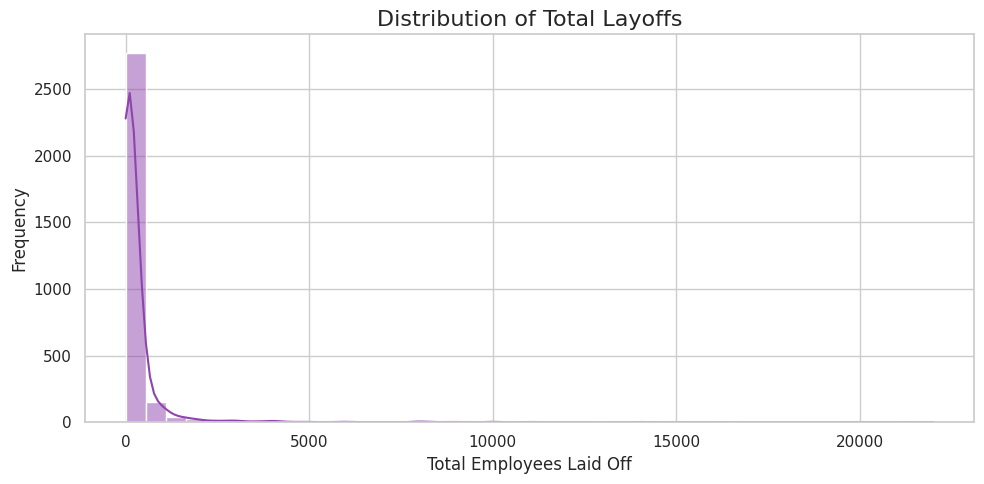

In [15]:

plt.figure(figsize=(10, 5))

sns.histplot(
    df['total_laid_off'],
    bins=40,
    kde=True,
    color='#8E44AD'
)

plt.title('Distribution of Total Layoffs', fontsize=16)
plt.xlabel('Total Employees Laid Off')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


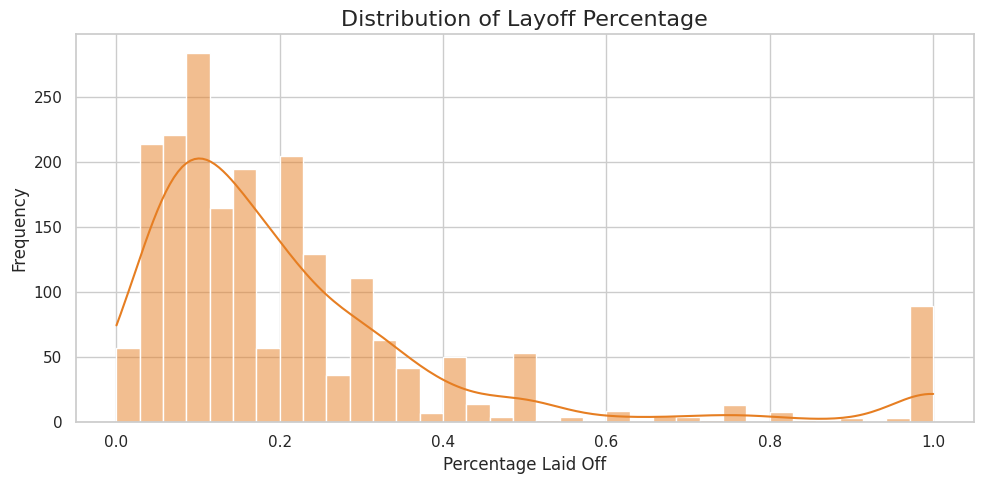

In [16]:

plt.figure(figsize=(10, 5))

sns.histplot(
    df['percentage_laid_off'].dropna(),
    bins=35,
    kde=True,
    color='#E67E22'
)

plt.title('Distribution of Layoff Percentage', fontsize=16)
plt.xlabel('Percentage Laid Off')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


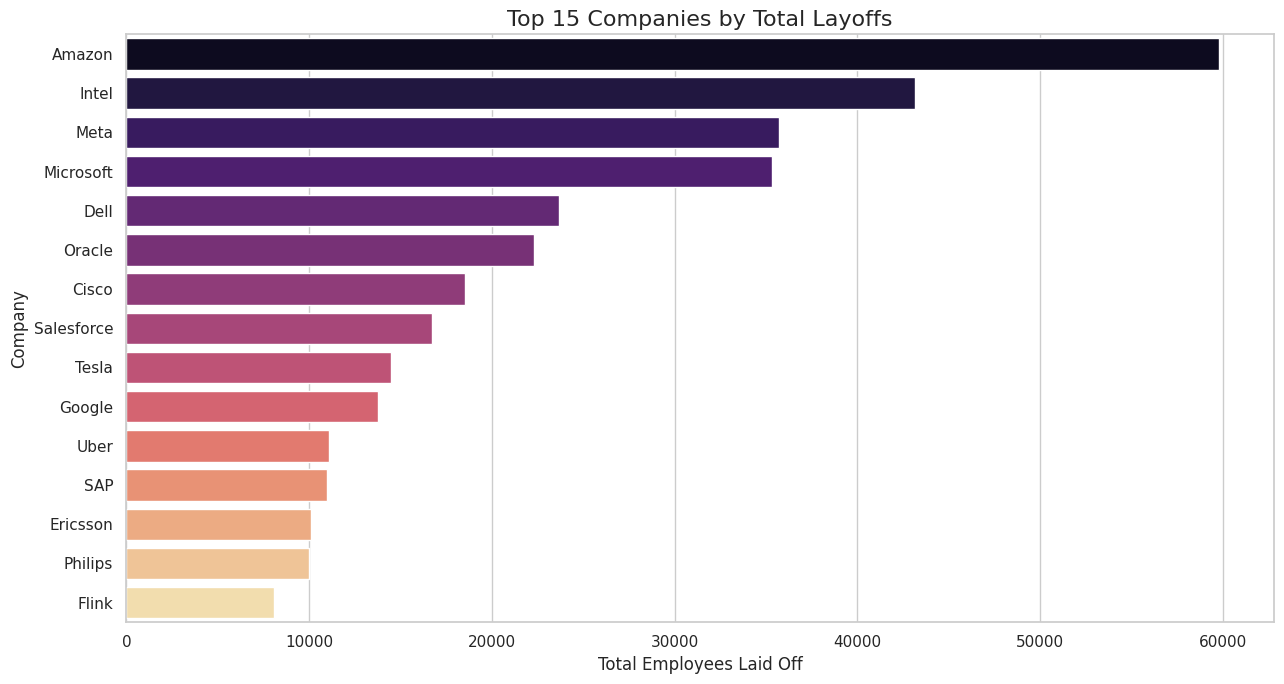

In [17]:

top_companies = (
    df.groupby('company')['total_laid_off']
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(13, 7))

sns.barplot(
    x=top_companies.values,
    y=top_companies.index,
    hue=top_companies.index,
    palette='magma',
    legend=False
)

plt.title('Top 15 Companies by Total Layoffs', fontsize=16)
plt.xlabel('Total Employees Laid Off')
plt.ylabel('Company')
plt.tight_layout()
plt.show()


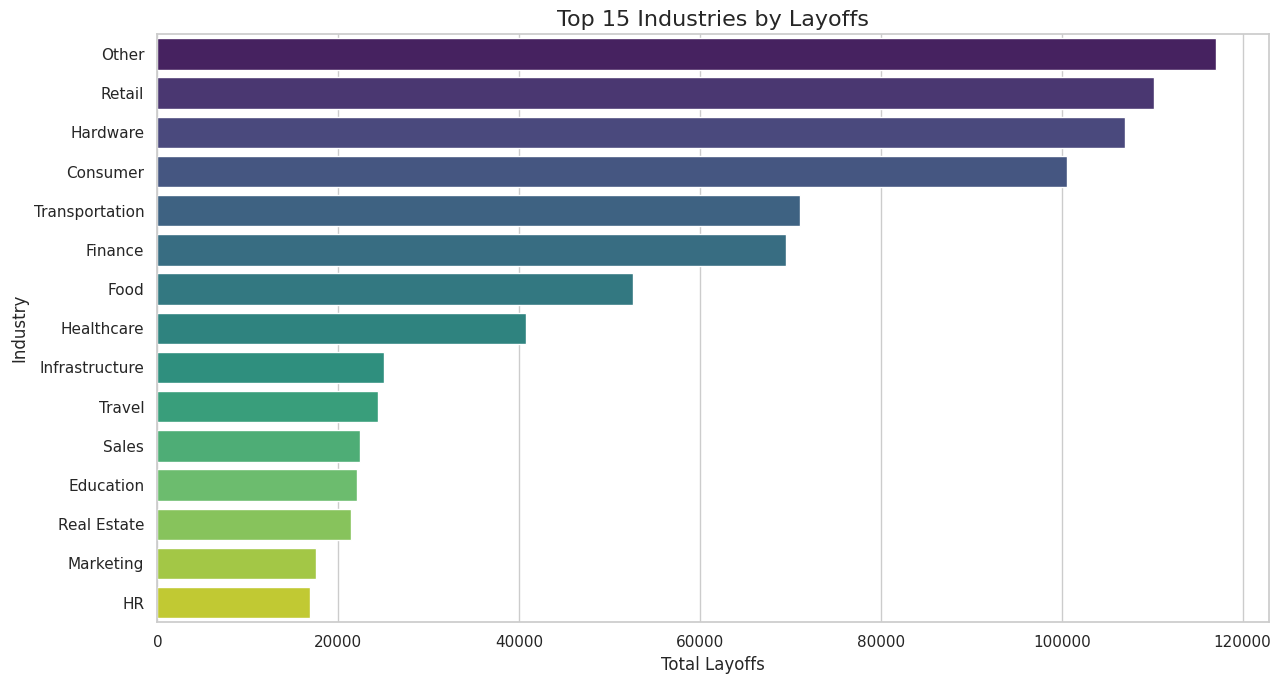

In [18]:

industry_layoffs = (
    df.groupby('industry')['total_laid_off']
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(13, 7))

sns.barplot(
    x=industry_layoffs.values,
    y=industry_layoffs.index,
    hue=industry_layoffs.index,
    palette='viridis',
    legend=False
)

plt.title('Top 15 Industries by Layoffs', fontsize=16)
plt.xlabel('Total Layoffs')
plt.ylabel('Industry')
plt.tight_layout()
plt.show()


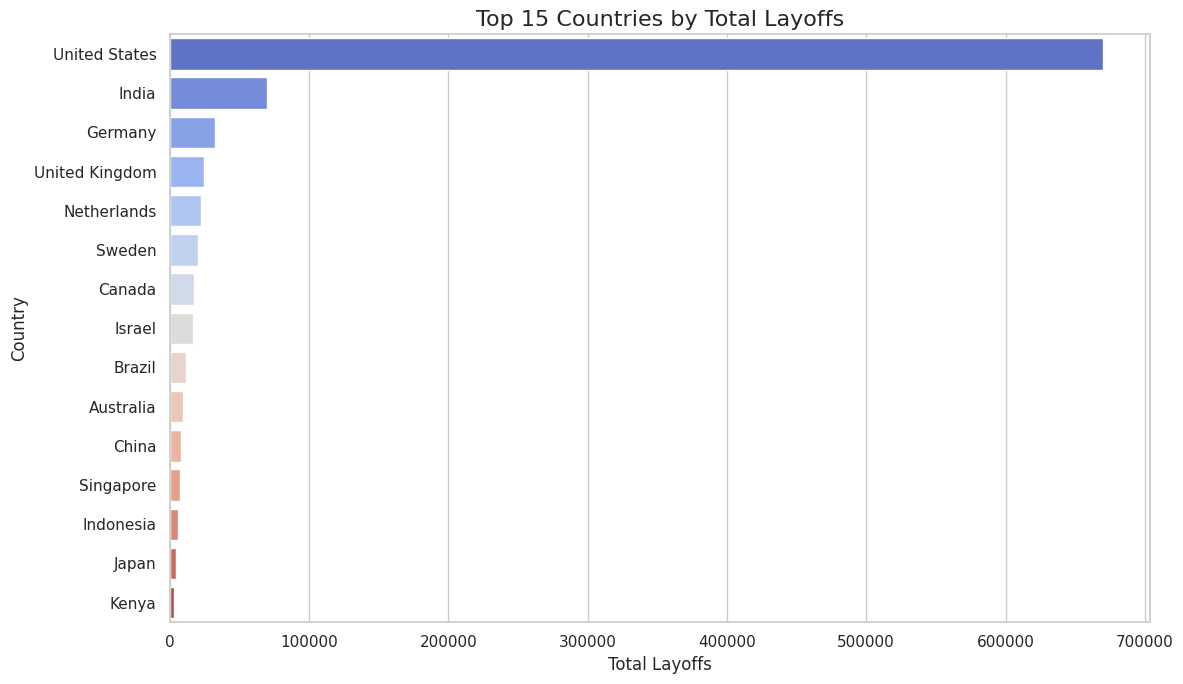

In [19]:

country_layoffs = (
    df.groupby('country')['total_laid_off']
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=country_layoffs.values,
    y=country_layoffs.index,
    hue=country_layoffs.index,
    palette='coolwarm',
    legend=False
)

plt.title('Top 15 Countries by Total Layoffs', fontsize=16)
plt.xlabel('Total Layoffs')
plt.ylabel('Country')
plt.tight_layout()
plt.show()


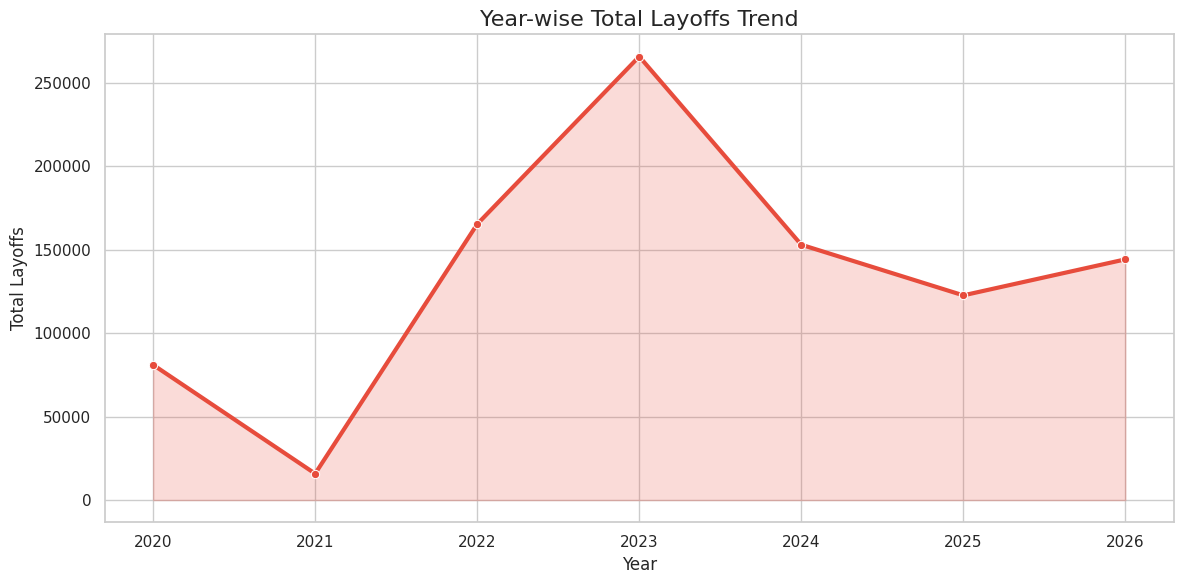

In [20]:

year_layoffs = df.groupby('year')['total_laid_off'].sum().dropna()

plt.figure(figsize=(12, 6))

sns.lineplot(
    x=year_layoffs.index,
    y=year_layoffs.values,
    marker='o',
    linewidth=3,
    color='#E74C3C'
)

plt.fill_between(
    year_layoffs.index,
    year_layoffs.values,
    alpha=0.2,
    color='#E74C3C'
)

plt.title('Year-wise Total Layoffs Trend', fontsize=16)
plt.xlabel('Year')
plt.ylabel('Total Layoffs')
plt.tight_layout()
plt.show()


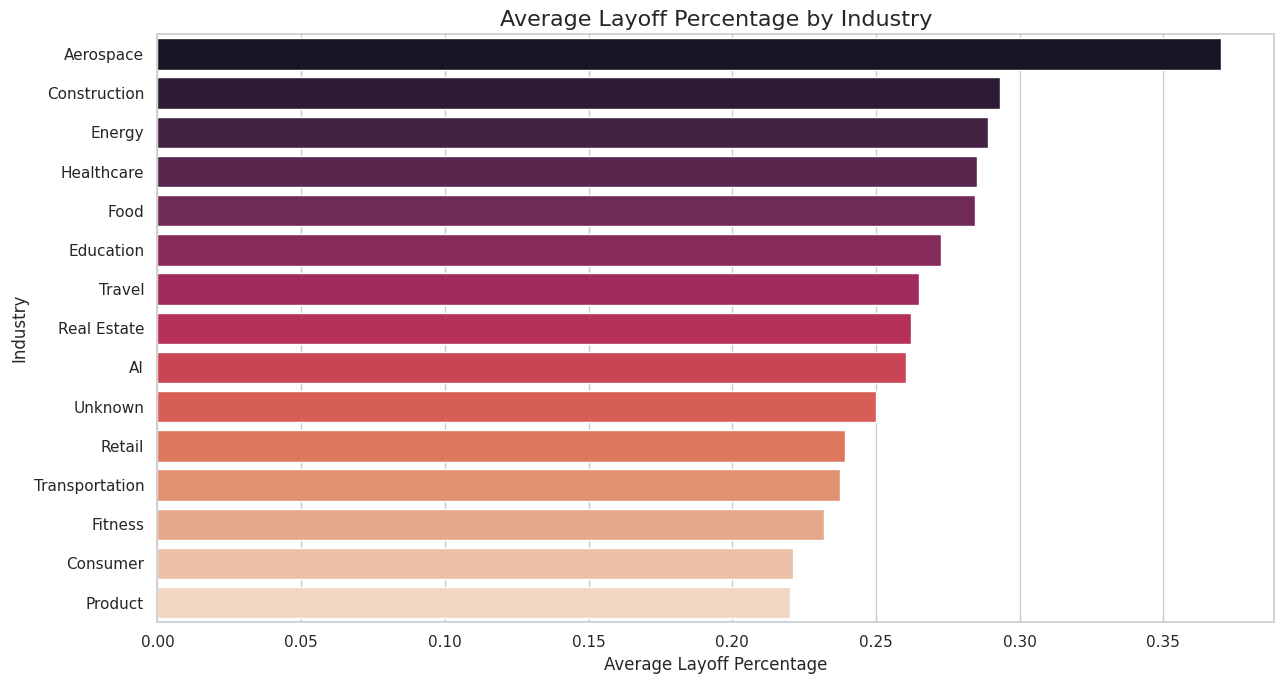

In [21]:

industry_percentage = (
    df.groupby('industry')['percentage_laid_off']
    .mean()
    .dropna()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(13, 7))

sns.barplot(
    x=industry_percentage.values,
    y=industry_percentage.index,
    hue=industry_percentage.index,
    palette='rocket',
    legend=False
)

plt.title('Average Layoff Percentage by Industry', fontsize=16)
plt.xlabel('Average Layoff Percentage')
plt.ylabel('Industry')
plt.tight_layout()
plt.show()


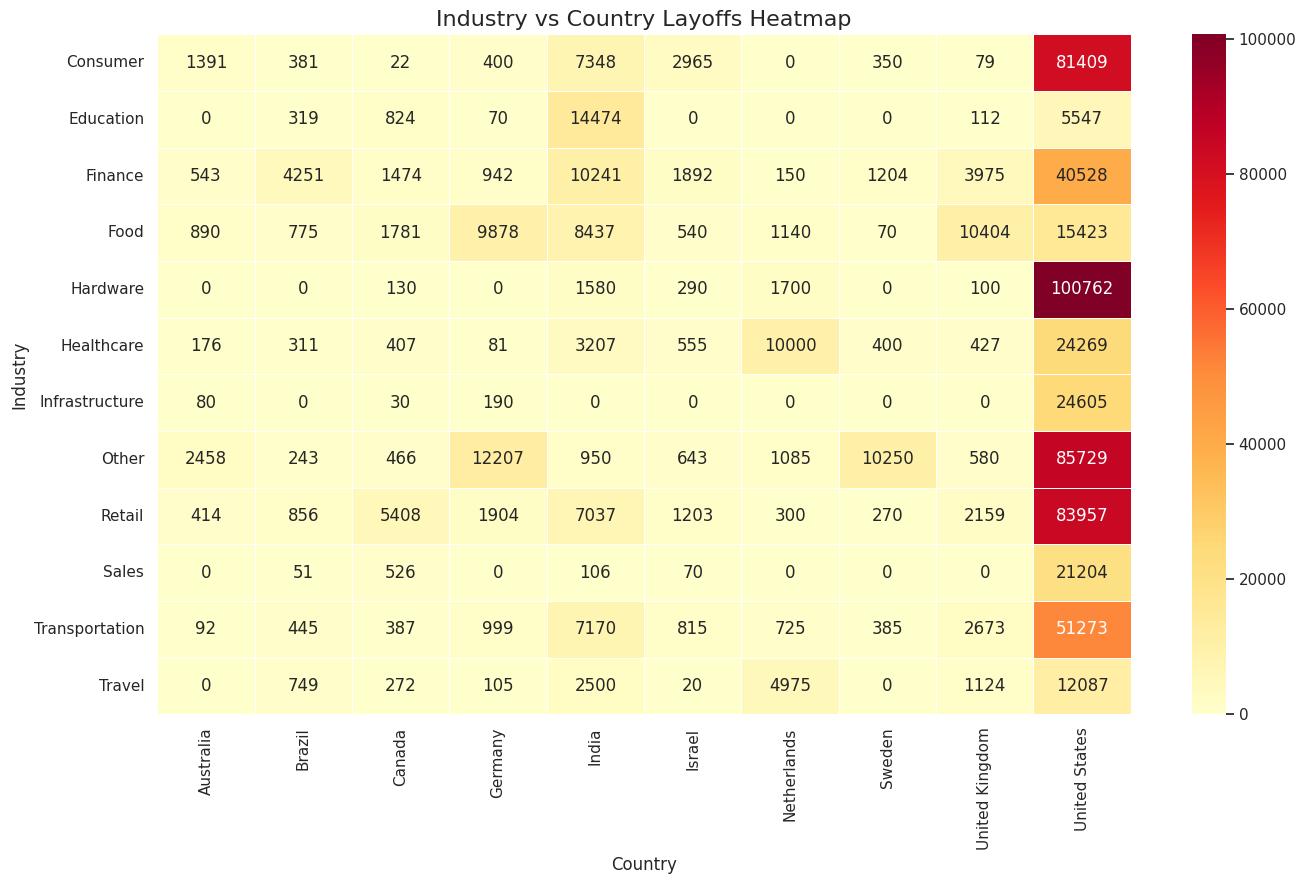

In [22]:

heatmap_data = df.pivot_table(
    index='industry',
    columns='country',
    values='total_laid_off',
    aggfunc='sum',
    fill_value=0
)

# Select top industries and countries
top_industries = df.groupby('industry')['total_laid_off'].sum().nlargest(12).index
top_countries = df.groupby('country')['total_laid_off'].sum().nlargest(10).index

heatmap_data = heatmap_data.loc[
    heatmap_data.index.intersection(top_industries),
    heatmap_data.columns.intersection(top_countries)
]

plt.figure(figsize=(14, 9))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.0f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('Industry vs Country Layoffs Heatmap', fontsize=16)
plt.xlabel('Country')
plt.ylabel('Industry')
plt.tight_layout()
plt.show()


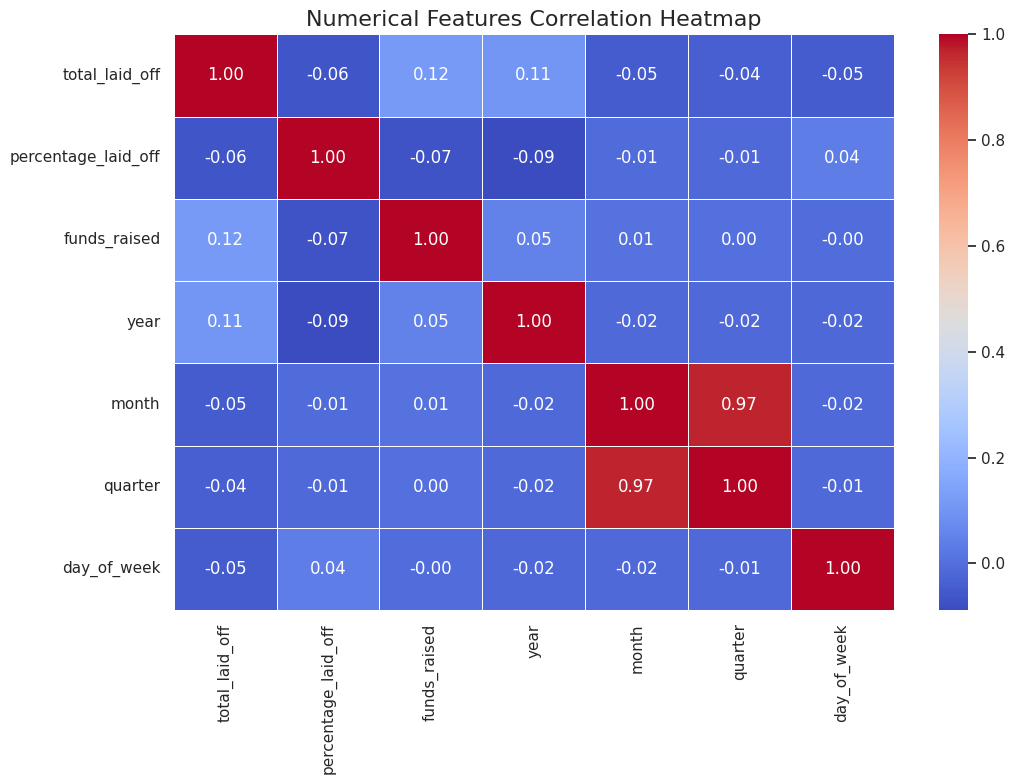

In [23]:

plt.figure(figsize=(11, 8))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Numerical Features Correlation Heatmap', fontsize=16)
plt.tight_layout()
plt.show()


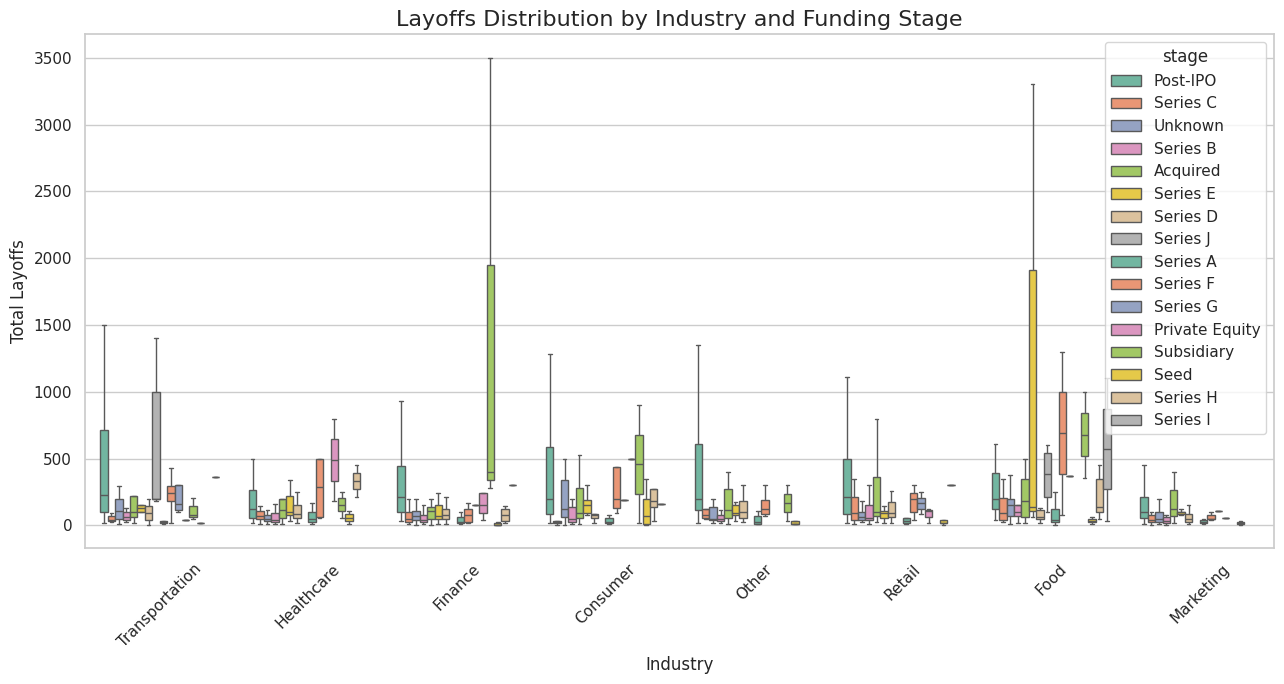

In [24]:

plt.figure(figsize=(13, 7))

sns.boxplot(
    data=df[df['industry'].isin(
        df['industry'].value_counts().head(8).index
    )],
    x='industry',
    y='total_laid_off',
    hue='stage',
    palette='Set2',
    showfliers=False
)

plt.title('Layoffs Distribution by Industry and Funding Stage', fontsize=16)
plt.xlabel('Industry')
plt.ylabel('Total Layoffs')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Median Layoffs Threshold: 90.0

Target Distribution:
Layoff_Category
0    1533
1    1515
Name: count, dtype: int64

Target Labels:
0 = Lower or equal layoffs
1 = Higher layoffs


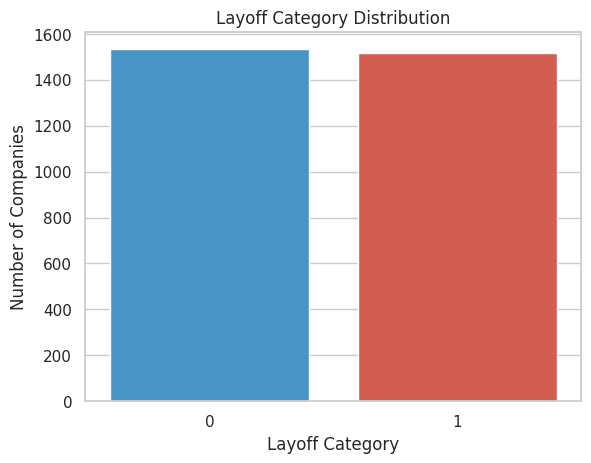

In [25]:

# ============================================
# CREATE TARGET VARIABLE
# ============================================

threshold = df['total_laid_off'].median()

df['Layoff_Category'] = (
    df['total_laid_off'] > threshold
).astype(int)

print("Median Layoffs Threshold:", threshold)

print("\nTarget Distribution:")
print(df['Layoff_Category'].value_counts())

print("\nTarget Labels:")
print("0 = Lower or equal layoffs")
print("1 = Higher layoffs")

sns.countplot(
    data=df,
    x='Layoff_Category',
    hue='Layoff_Category',
    palette=['#3498DB', '#E74C3C'],
    legend=False
)

plt.title('Layoff Category Distribution')
plt.xlabel('Layoff Category')
plt.ylabel('Number of Companies')
plt.show()


## Feature engineering

In [26]:

# ============================================
# FEATURE SELECTION
# ============================================

X = df[
    [
        'location',
        'industry',
        'stage',
        'funds_raised',
        'country',
        'year',
        'month',
        'quarter',
        'day_of_week'
    ]
].copy()

y = df['Layoff_Category'].copy()

# Identify categorical and numerical columns
categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

print("Categorical Features:", categorical_features)
print("Numerical Features:", numerical_features)

# Train-test split BEFORE fitting encoders or scalers
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Categorical Features: ['location', 'industry', 'stage', 'country']
Numerical Features: ['funds_raised', 'year', 'month', 'quarter', 'day_of_week']

Training Data: (2438, 9)
Testing Data: (610, 9)


In [27]:

from sklearn.preprocessing import OrdinalEncoder

# ============================================
# PREPROCESSING PIPELINE
# ============================================

numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(
            handle_unknown='use_encoded_value',
            unknown_value=-1
        ))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

print("\nPreprocessing Completed!")


Processed Training Shape: (2438, 9)
Processed Testing Shape: (610, 9)

Preprocessing Completed!


In [28]:

# ============================================
# MACHINE LEARNING MODELS
# ============================================

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        class_weight='balanced'
    ),

    'Decision Tree': DecisionTreeClassifier(
        max_depth=8,
        random_state=42,
        class_weight='balanced'
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=5
    ),

    'SVM': SVC(
        probability=True,
        class_weight='balanced',
        random_state=42
    ),

    'Naive Bayes': GaussianNB(),

    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ),

    'Extra Trees': ExtraTreesClassifier(
        n_estimators=200,
        max_depth=12,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ),

    'AdaBoost': AdaBoostClassifier(
        n_estimators=100,
        learning_rate=0.5,
        random_state=42
    )
}

# ============================================
# MODEL TRAINING AND EVALUATION
# ============================================

results = []
trained_models = {}

for name, model in models.items():

    print("\n" + "="*60)
    print("MODEL:", name)
    print("="*60)

    model.fit(X_train_processed, y_train)

    y_pred = model.predict(X_test_processed)

    y_prob = model.predict_proba(X_test_processed)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)

    results.append({
        'Model': name,
        'Accuracy': accuracy * 100,
        'Precision': precision * 100,
        'Recall': recall * 100,
        'F1 Score': f1 * 100,
        'ROC AUC': auc
    })

    trained_models[name] = model

    print(f"Accuracy  : {accuracy*100:.2f}%")
    print(f"Precision : {precision*100:.2f}%")
    print(f"Recall    : {recall*100:.2f}%")
    print(f"F1 Score  : {f1*100:.2f}%")
    print(f"ROC AUC   : {auc:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))



MODEL: Logistic Regression
Accuracy  : 65.74%
Precision : 67.15%
Recall    : 60.73%
F1 Score  : 63.78%
ROC AUC   : 0.6873

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.71      0.67       307
           1       0.67      0.61      0.64       303

    accuracy                           0.66       610
   macro avg       0.66      0.66      0.66       610
weighted avg       0.66      0.66      0.66       610


MODEL: Decision Tree
Accuracy  : 68.85%
Precision : 67.49%
Recall    : 71.95%
F1 Score  : 69.65%
ROC AUC   : 0.7222

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.66      0.68       307
           1       0.67      0.72      0.70       303

    accuracy                           0.69       610
   macro avg       0.69      0.69      0.69       610
weighted avg       0.69      0.69      0.69       610


MODEL: Random Forest
Accuracy  : 69.34%
Precision : 68.24

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
2,Random Forest,69.34%,68.24%,71.62%,69.89%,0.7929
7,Extra Trees,72.30%,73.10%,69.97%,71.50%,0.7870
6,Gradient Boosting,70.00%,68.52%,73.27%,70.81%,0.7750
8,AdaBoost,69.18%,70.18%,66.01%,68.03%,0.7726
1,Decision Tree,68.85%,67.49%,71.95%,69.65%,0.7222
5,Naive Bayes,58.85%,70.97%,29.04%,41.22%,0.6897
0,Logistic Regression,65.74%,67.15%,60.73%,63.78%,0.6873
3,KNN,62.62%,63.16%,59.41%,61.22%,0.6556
4,SVM,53.61%,52.58%,67.33%,59.04%,0.6074


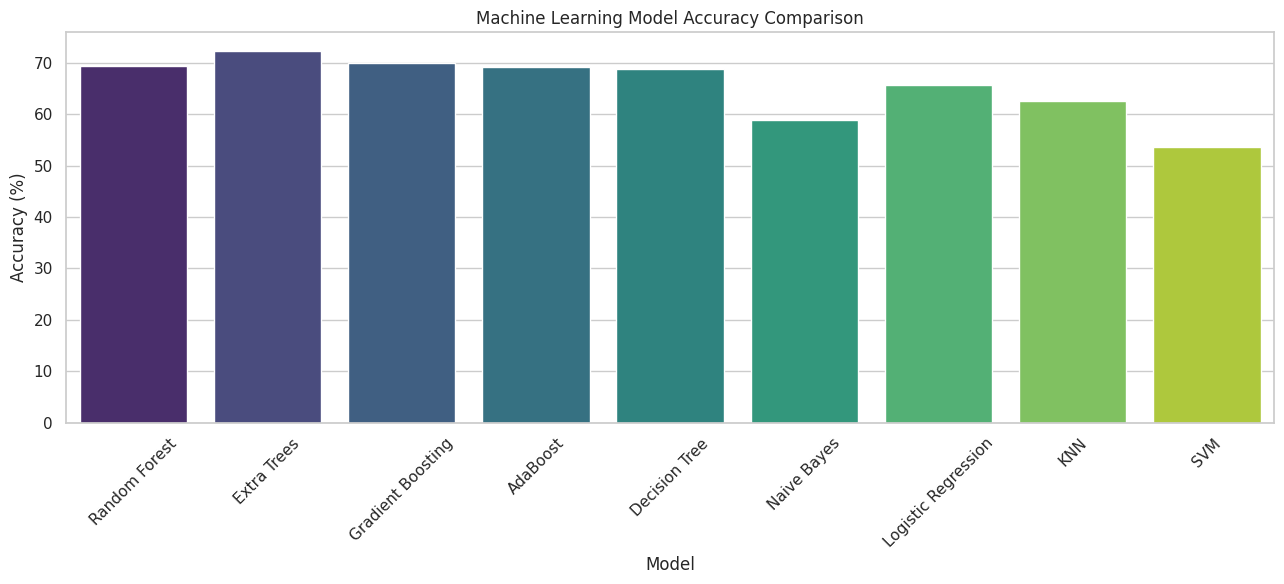

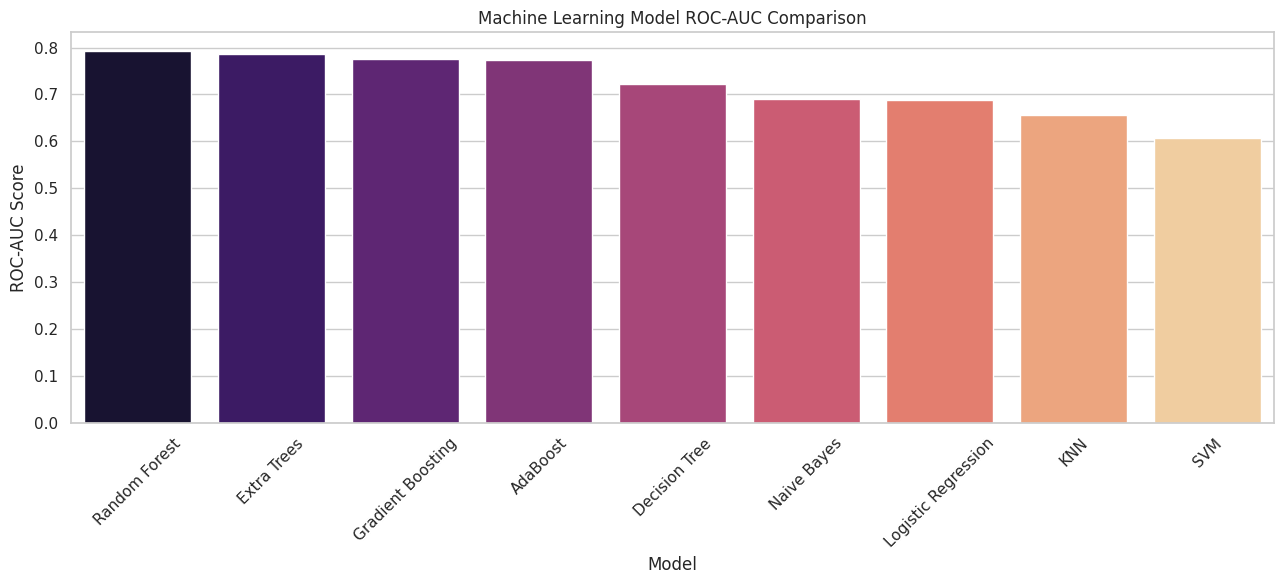

In [29]:

# ============================================
# MODEL COMPARISON
# ============================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='ROC AUC',
    ascending=False
)

display(
    results_df.style.background_gradient(
        cmap='YlGn'
    ).format({
        'Accuracy': '{:.2f}%',
        'Precision': '{:.2f}%',
        'Recall': '{:.2f}%',
        'F1 Score': '{:.2f}%',
        'ROC AUC': '{:.4f}'
    })
)

# Accuracy comparison
plt.figure(figsize=(13, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy',
    hue='Model',
    palette='viridis',
    legend=False
)

plt.title('Machine Learning Model Accuracy Comparison')
plt.ylabel('Accuracy (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ROC-AUC comparison
plt.figure(figsize=(13, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='ROC AUC',
    hue='Model',
    palette='magma',
    legend=False
)

plt.title('Machine Learning Model ROC-AUC Comparison')
plt.ylabel('ROC-AUC Score')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


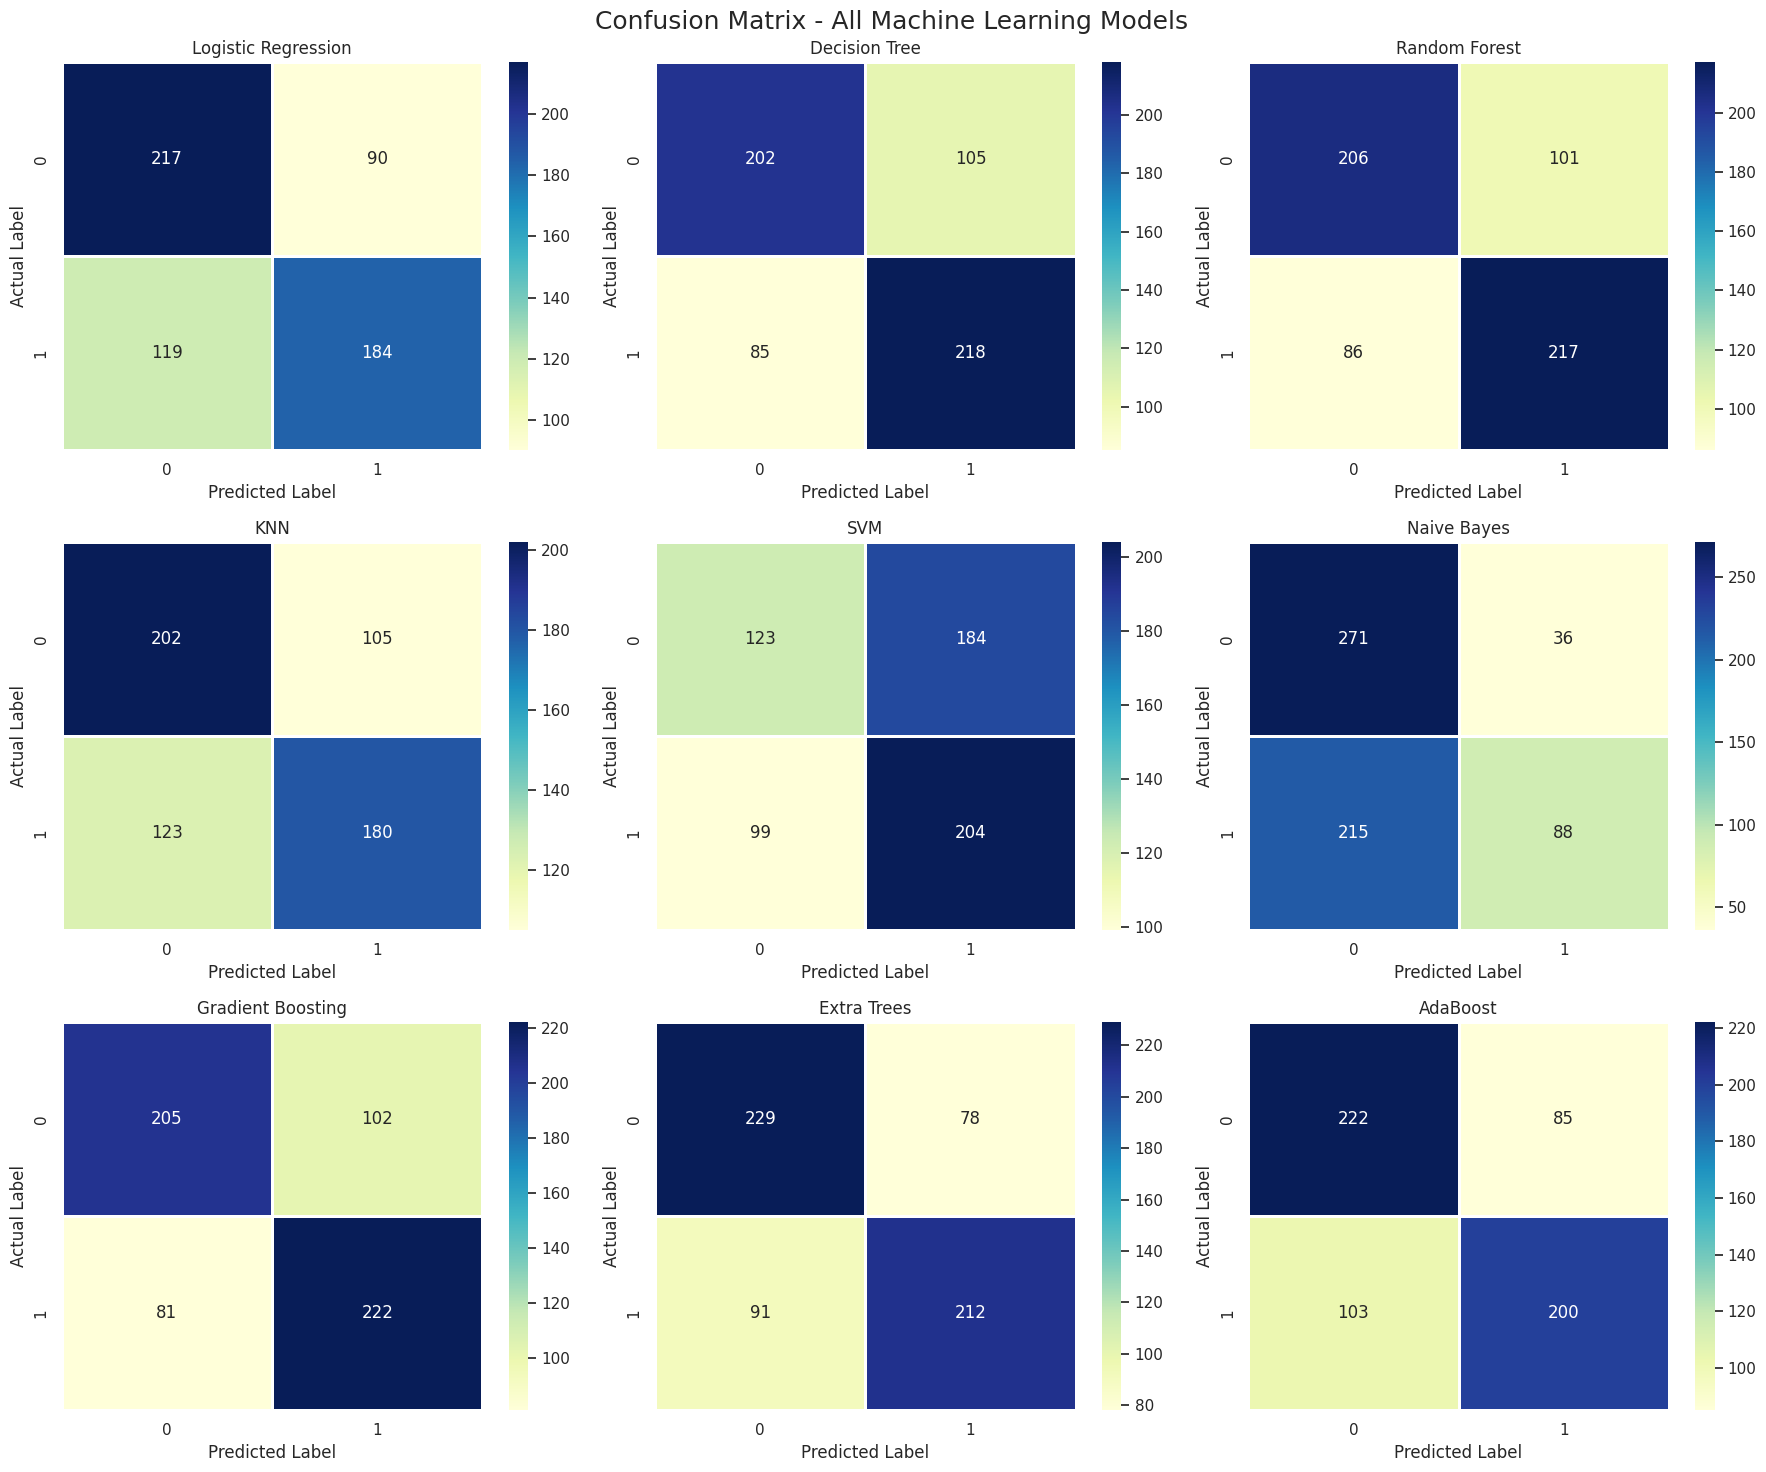

In [30]:

# ============================================
# CONFUSION MATRICES
# ============================================

fig, axes = plt.subplots(
    3, 3,
    figsize=(18, 15)
)

axes = axes.flatten()

for i, (name, model) in enumerate(trained_models.items()):

    y_pred = model.predict(X_test_processed)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='YlGnBu',
        ax=axes[i],
        linewidths=1
    )

    axes[i].set_title(name)
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('Actual Label')

plt.suptitle(
    'Confusion Matrix - All Machine Learning Models',
    fontsize=18
)

plt.tight_layout()
plt.show()


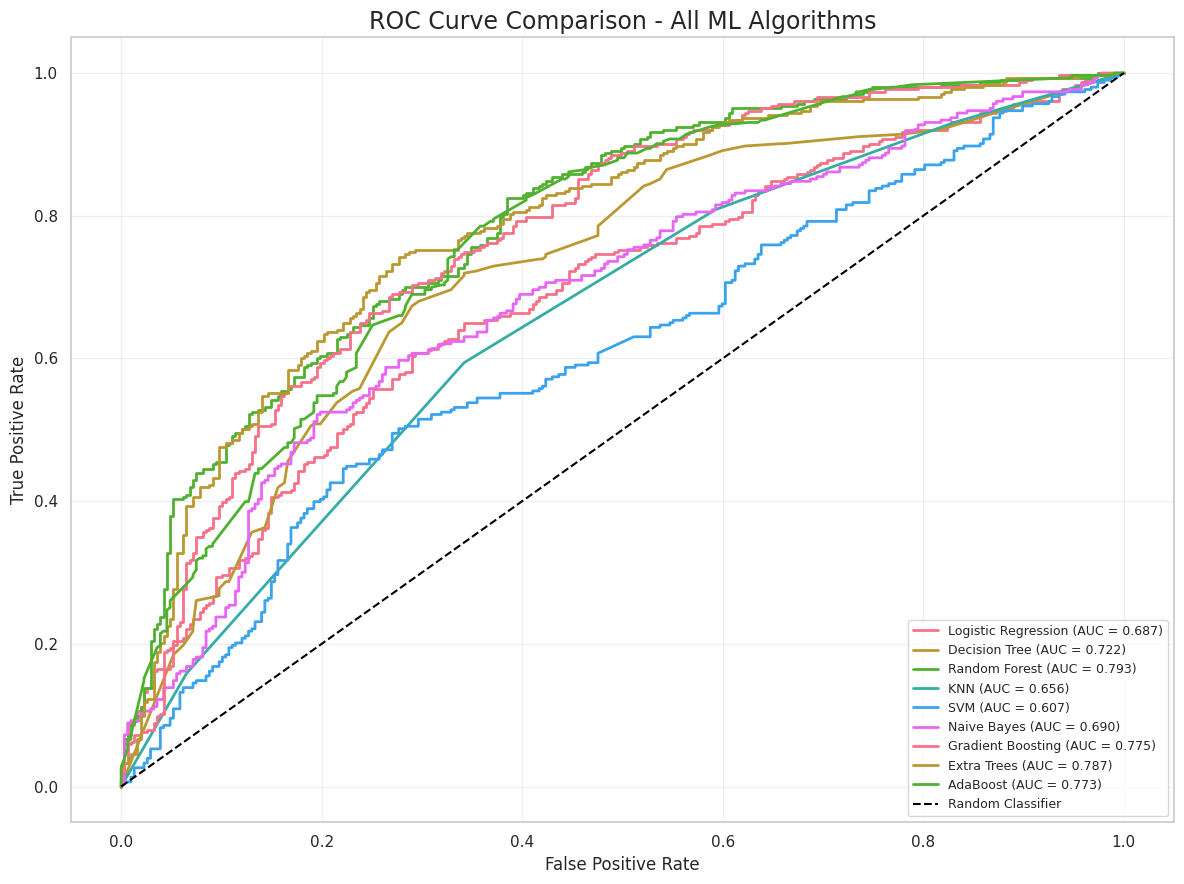

In [31]:

# ============================================
# ROC CURVE FOR ALL MODELS
# ============================================

plt.figure(figsize=(12, 9))

for name, model in trained_models.items():

    y_prob = model.predict_proba(
        X_test_processed
    )[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_prob
    )

    auc_score = roc_auc_score(
        y_test,
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f'{name} (AUC = {auc_score:.3f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='black',
    label='Random Classifier'
)

plt.title(
    'ROC Curve Comparison - All ML Algorithms',
    fontsize=17
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.legend(
    loc='lower right',
    fontsize=9
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Best Model: Random Forest

Final Classification Report:
                precision    recall  f1-score   support

 Lower Layoffs       0.71      0.67      0.69       307
Higher Layoffs       0.68      0.72      0.70       303

      accuracy                           0.69       610
     macro avg       0.69      0.69      0.69       610
  weighted avg       0.69      0.69      0.69       610

Best Model Accuracy: 69.34 %
Best Model ROC-AUC: 0.7929


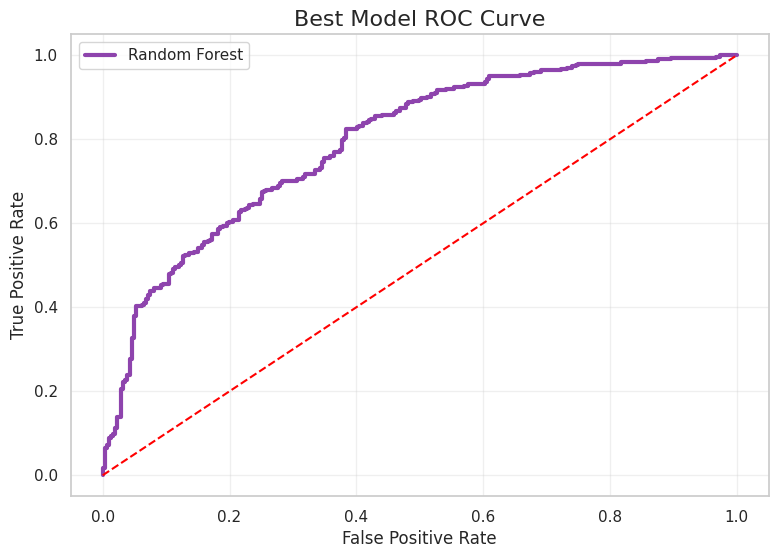

In [32]:

# ============================================
# SELECT BEST MODEL BASED ON ROC-AUC
# ============================================

best_model_name = results_df.iloc[0]['Model']

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

best_predictions = best_model.predict(
    X_test_processed
)

best_probabilities = best_model.predict_proba(
    X_test_processed
)[:, 1]

print("\nFinal Classification Report:")
print(classification_report(
    y_test,
    best_predictions,
    target_names=['Lower Layoffs', 'Higher Layoffs'],
    zero_division=0
))

print("Best Model Accuracy:",
      round(accuracy_score(y_test, best_predictions)*100, 2), "%")

print("Best Model ROC-AUC:",
      round(roc_auc_score(y_test, best_probabilities), 4))

# Final ROC curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    best_probabilities
)

plt.figure(figsize=(9, 6))

plt.plot(
    fpr,
    tpr,
    color='#8E44AD',
    linewidth=3,
    label=f'{best_model_name}'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='red'
)

plt.title('Best Model ROC Curve', fontsize=16)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


,Feature,Importance
0,num__funds_raised,0.281183
7,cat__stage,0.159415
5,cat__location,0.118428
6,cat__industry,0.115040
2,num__month,0.081162
8,cat__country,0.071642
1,num__year,0.069037
4,num__day_of_week,0.068421
3,num__quarter,0.035672


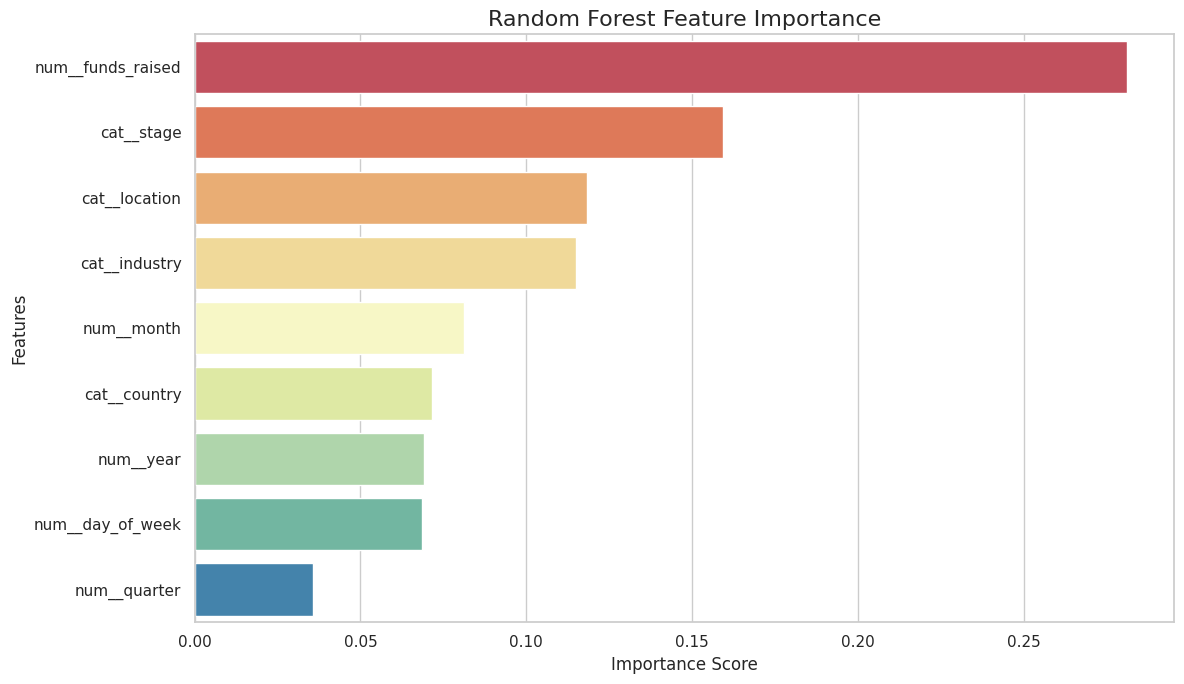

In [33]:

# ============================================
# FEATURE IMPORTANCE
# ============================================

rf_model = trained_models['Random Forest']

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

display(importance_df)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='Spectral',
    legend=False
)

plt.title('Random Forest Feature Importance', fontsize=16)
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()


## Thank you..pls upvote!!!!!!!!!!